# Прогнозирование погоды с помощью нейронных сетей (PyTorch)

Учебный курс "[Программирование глубоких нейронных сетей на Python](https://openedu.ru/course/urfu/PYDNN/)".

За основу взят [ноутбук по анализу временных рядов из книги Deel Learning With Python](https://github.com/fchollet/deep-learning-with-python-notebooks/blob/master/chapter13_timeseries-forecasting.ipynb).

In [1]:
import numpy as np
import zipfile
import os
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
%matplotlib inline

## Загружаем данные

In [2]:
data_path = 'data'

In [3]:
path = Path(data_path)

if not path.exists():
    path.mkdir(parents=True, exist_ok=True)

In [4]:
#!curl -s -L -o data/jena_climate_2009_2016.csv.zip "https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip"

In [5]:
# !wget --progress=bar:force -O data/jena_climate_2009_2016.csv.zip "https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip"

In [6]:
# with zipfile.ZipFile("data/jena_climate_2009_2016.csv.zip", 'r') as zip_ref:
#     zip_ref.extractall(data_path)

In [8]:
fname = os.path.join("./08_timeseries/data/jena_climate_2009_2016.csv")

with open(fname) as f:
    data = f.read()

lines = data.split("\n")
header = lines[0].split(",")
lines = lines[1:]
print(header)
print(len(lines))

['"Date Time"', '"p (mbar)"', '"T (degC)"', '"Tpot (K)"', '"Tdew (degC)"', '"rh (%)"', '"VPmax (mbar)"', '"VPact (mbar)"', '"VPdef (mbar)"', '"sh (g/kg)"', '"H2OC (mmol/mol)"', '"rho (g/m**3)"', '"wv (m/s)"', '"max. wv (m/s)"', '"wd (deg)"']
420451


## Готовим данные

Извлекаем данные о температуре

In [9]:
temperature = np.zeros((len(lines),))
raw_data = np.zeros((len(lines), len(header) - 1))

for i, line in enumerate(lines):
    values = [float(x) for x in line.split(",")[1:]]
    temperature[i] = values[1]
    raw_data[i, :] = values[:]

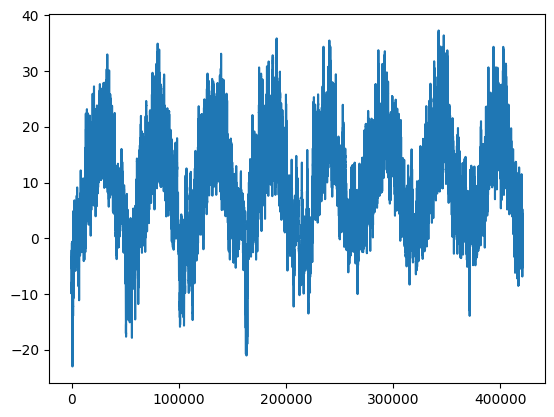

In [10]:
plt.plot(range(len(temperature)), temperature)

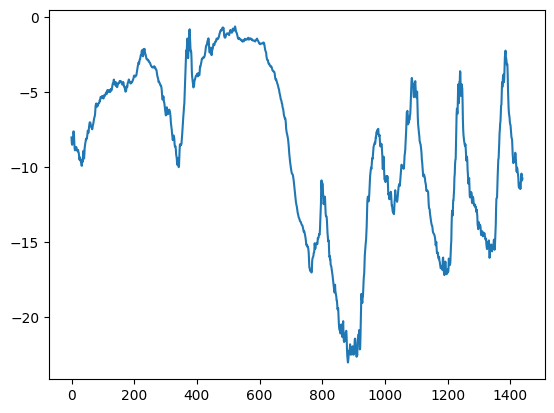

In [11]:
plt.plot(range(1440), temperature[:1440])

Разбиваем данные на обучающий, проверочный и тестовый наборы

In [12]:
num_train_samples = int(0.5 * len(raw_data))
num_val_samples = int(0.25 * len(raw_data))
num_test_samples = len(raw_data) - num_train_samples - num_val_samples
print("Количество измерений в обучающем наборе:", num_train_samples)
print("Количество измерений в проверочном наборе:", num_val_samples)
print("Количество измерений в тестовом наборе:", num_test_samples)

Количество измерений в обучающем наборе: 210225
Количество измерений в проверочном наборе: 105112
Количество измерений в тестовом наборе: 105114


Нормализуем данные

Признаки нормируем по статистикам обучающей части. **Цель (температуру) тоже нормируем** — берём её из уже нормированного `raw_data[:, 1]`. Для метрик и графиков денормируем обратно: `T_degC = T_norm * std[1] + mean[1]`.

In [13]:
mean = raw_data[:num_train_samples].mean(axis=0)
raw_data -= mean
std = raw_data[:num_train_samples].std(axis=0)
raw_data /= std

# Нормированная температура (столбец 1) — цель для моделей.
# Важно: цель и признаки должны быть в одном масштабе.
temperature_norm = raw_data[:, 1].copy()

## Визуализация данных

In [14]:
feature_names = header[1:]
print("Признаки:", feature_names)

Признаки: ['"p (mbar)"', '"T (degC)"', '"Tpot (K)"', '"Tdew (degC)"', '"rh (%)"', '"VPmax (mbar)"', '"VPact (mbar)"', '"VPdef (mbar)"', '"sh (g/kg)"', '"H2OC (mmol/mol)"', '"rho (g/m**3)"', '"wv (m/s)"', '"max. wv (m/s)"', '"wd (deg)"']


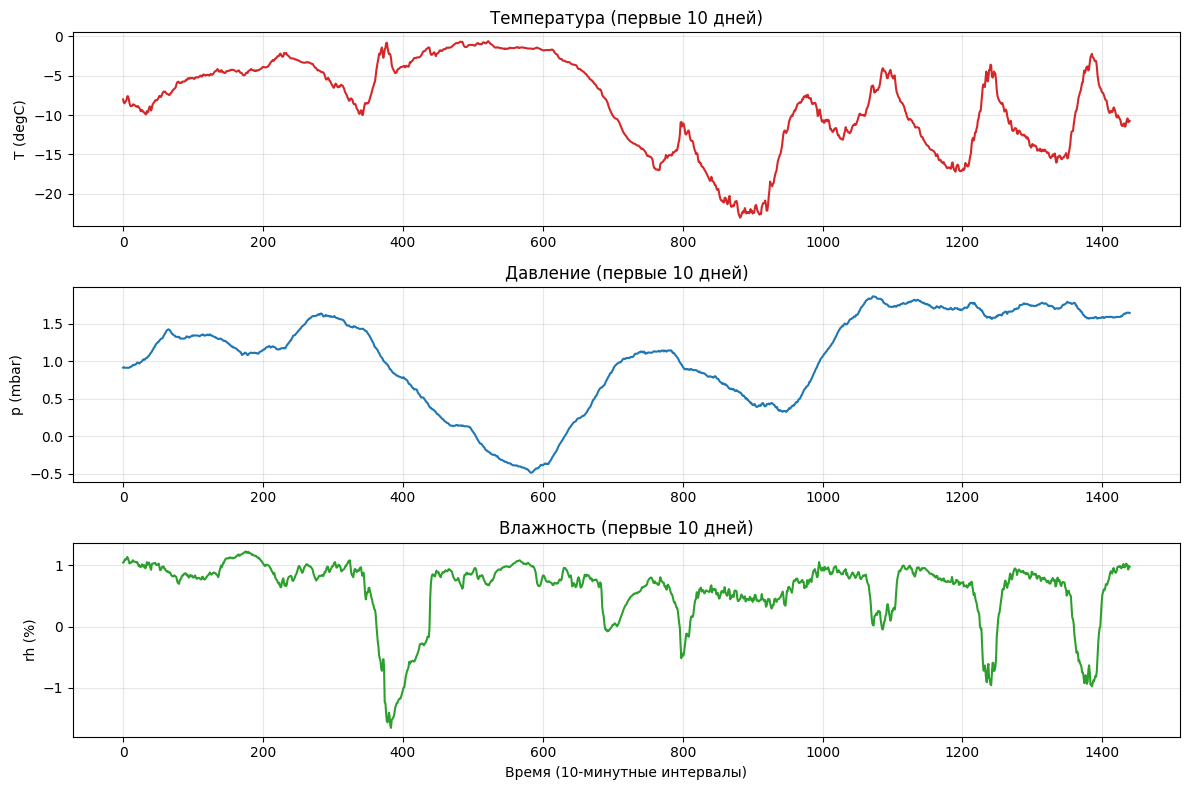

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8))

axes[0].plot(temperature[:1440], color='tab:red')
axes[0].set_title('Температура (первые 10 дней)')
axes[0].set_ylabel('T (degC)')
axes[0].grid(True, alpha=0.3)

axes[1].plot(raw_data[:1440, 0], color='tab:blue')
axes[1].set_title('Давление (первые 10 дней)')
axes[1].set_ylabel('p (mbar)')
axes[1].grid(True, alpha=0.3)

axes[2].plot(raw_data[:1440, 4], color='tab:green')
axes[2].set_title('Влажность (первые 10 дней)')
axes[2].set_ylabel('rh (%)')
axes[2].set_xlabel('Время (10-минутные интервалы)')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

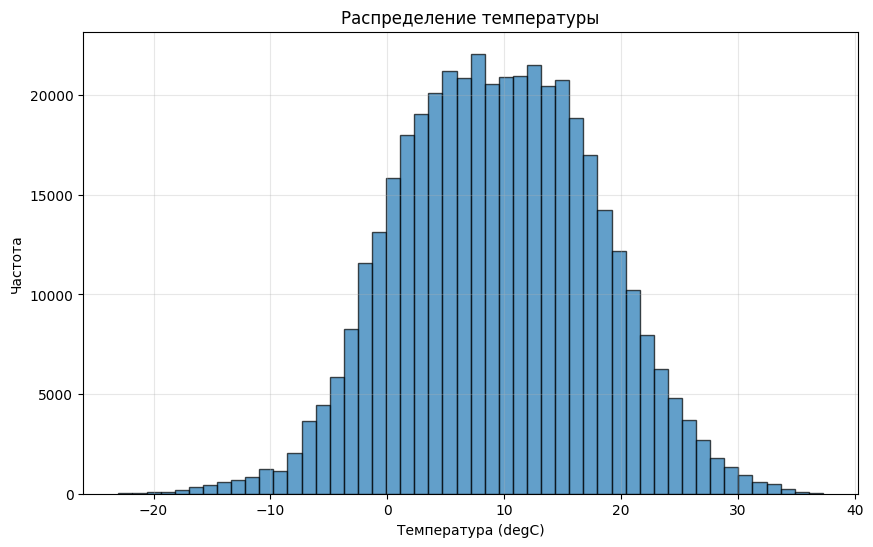

In [16]:
plt.figure(figsize=(10, 6))
plt.hist(temperature, bins=50, color='tab:blue', alpha=0.7, edgecolor='black')
plt.title('Распределение температуры')
plt.xlabel('Температура (degC)')
plt.ylabel('Частота')
plt.grid(True, alpha=0.3)
plt.show()

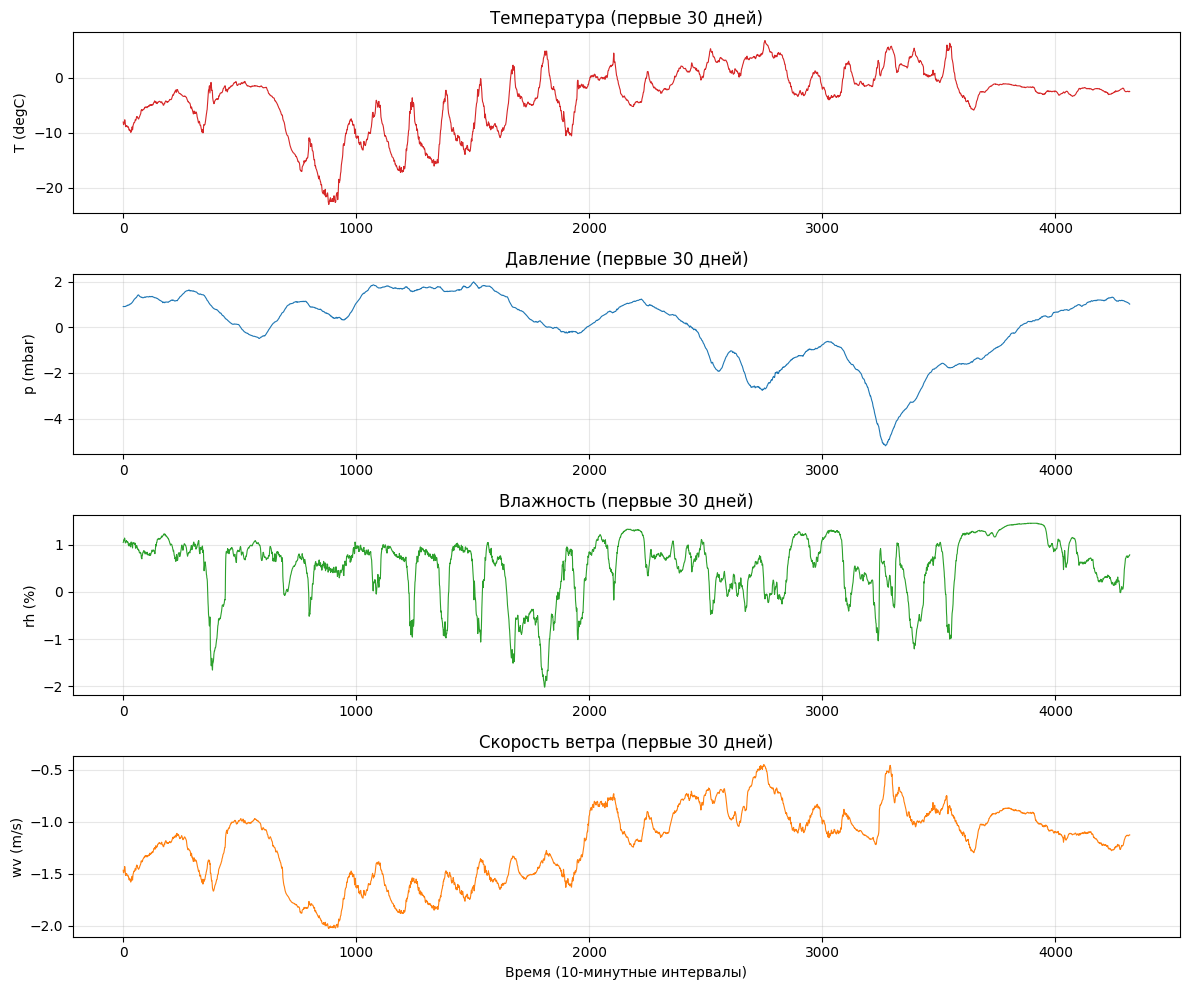

In [17]:
fig, axes = plt.subplots(4, 1, figsize=(12, 10))

days = 30
period = days * 144

axes[0].plot(temperature[:period], color='tab:red', linewidth=0.8)
axes[0].set_title(f'Температура (первые {days} дней)')
axes[0].set_ylabel('T (degC)')
axes[0].grid(True, alpha=0.3)

axes[1].plot(raw_data[:period, 0], color='tab:blue', linewidth=0.8)
axes[1].set_title(f'Давление (первые {days} дней)')
axes[1].set_ylabel('p (mbar)')
axes[1].grid(True, alpha=0.3)

axes[2].plot(raw_data[:period, 4], color='tab:green', linewidth=0.8)
axes[2].set_title(f'Влажность (первые {days} дней)')
axes[2].set_ylabel('rh (%)')
axes[2].grid(True, alpha=0.3)

axes[3].plot(raw_data[:period, 6], color='tab:orange', linewidth=0.8)
axes[3].set_title(f'Скорость ветра (первые {days} дней)')
axes[3].set_ylabel('wv (m/s)')
axes[3].set_xlabel('Время (10-минутные интервалы)')
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

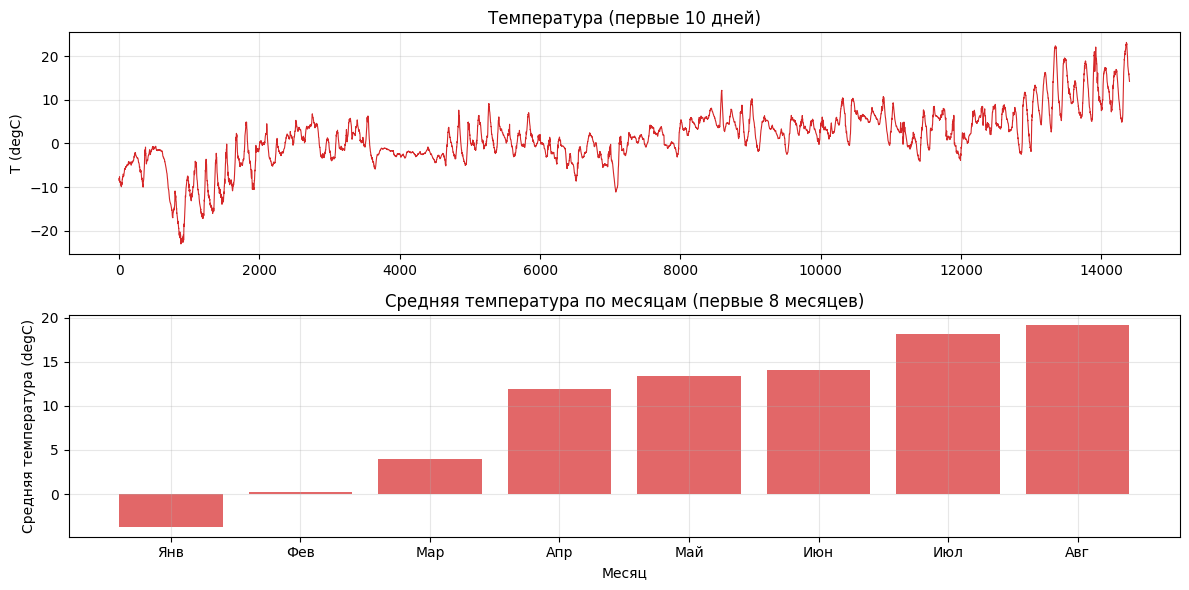

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6))

axes[0].plot(temperature[:14400], color='tab:red', linewidth=0.8)
axes[0].set_title('Температура (первые 10 дней)')
axes[0].set_ylabel('T (degC)')
axes[0].grid(True, alpha=0.3)

monthly_means = [np.mean(temperature[i*4320:(i+1)*4320]) for i in range(8)]  # ~30 дней * 144 измерения/день
axes[1].bar(range(8), monthly_means, color='tab:red', alpha=0.7)
axes[1].set_title('Средняя температура по месяцам (первые 8 месяцев)')
axes[1].set_xlabel('Месяц')
axes[1].set_ylabel('Средняя температура (degC)')
axes[1].set_xticks(range(8))
axes[1].set_xticklabels(['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн', 'Июл', 'Авг'])
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

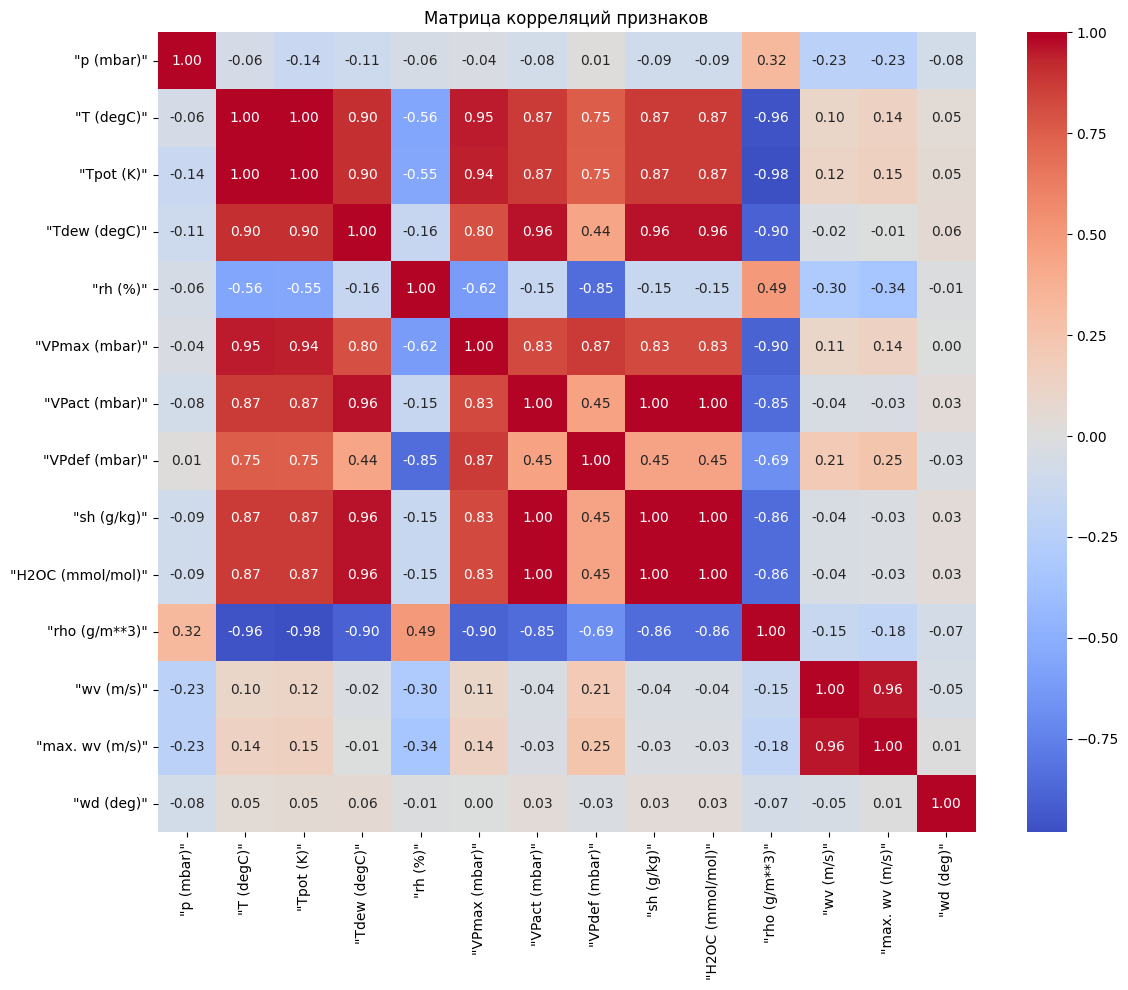

In [19]:
import seaborn as sns

correlation_matrix = np.corrcoef(raw_data[:num_train_samples].T)

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            xticklabels=feature_names, yticklabels=feature_names)
plt.title('Матрица корреляций признаков')
plt.tight_layout()
plt.show()

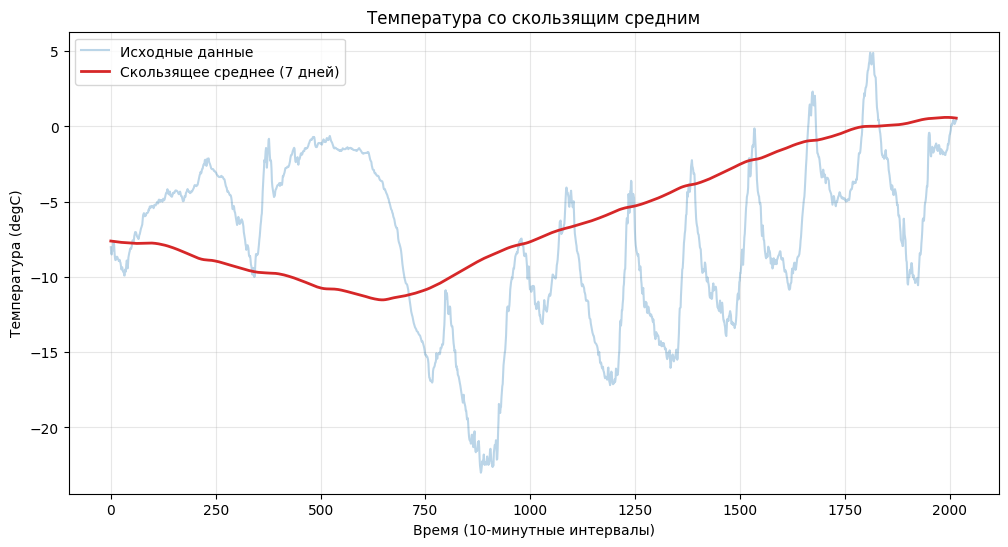

In [20]:
plt.figure(figsize=(12, 6))

window_size = 144 * 7  # 7 дней
rolling_mean = np.convolve(temperature, np.ones(window_size)/window_size, mode='valid')

plt.plot(temperature[:window_size*2], alpha=0.3, label='Исходные данные', color='tab:blue')
plt.plot(rolling_mean[:window_size*2], label=f'Скользящее среднее ({window_size // 144} дней)', 
         color='tab:red', linewidth=2)
plt.title('Температура со скользящим средним')
plt.xlabel('Время (10-минутные интервалы)')
plt.ylabel('Температура (degC)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

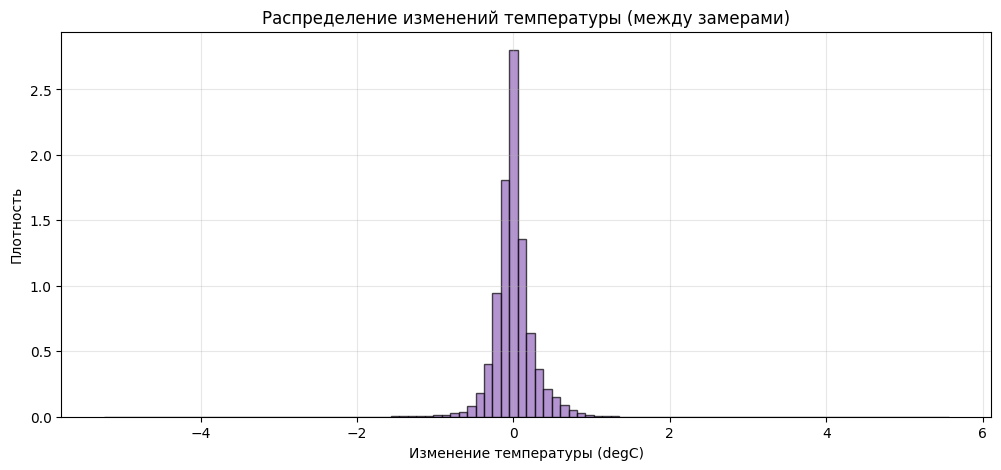

Среднее изменение: 0.0000 degC
Стд. отклонение изменений: 0.2484 degC
Максимальное увеличение: 5.5700 degC
Максимальное уменьшение: -5.2400 degC


In [21]:
plt.figure(figsize=(12, 5))

temp_diff = np.diff(temperature)
plt.hist(temp_diff, bins=100, color='tab:purple', alpha=0.7, edgecolor='black', density=True)
plt.title('Распределение изменений температуры (между замерами)')
plt.xlabel('Изменение температуры (degC)')
plt.ylabel('Плотность')
plt.grid(True, alpha=0.3)
plt.show()

print(f'Среднее изменение: {np.mean(temp_diff):.4f} degC')
print(f'Стд. отклонение изменений: {np.std(temp_diff):.4f} degC')
print(f'Максимальное увеличение: {np.max(temp_diff):.4f} degC')
print(f'Максимальное уменьшение: {np.min(temp_diff):.4f} degC')

## Создаем Dataset для PyTorch

In [22]:
class TimeSeriesDataset(Dataset):
    def __init__(self, data, targets, sampling_rate, sequence_length):
        self.data = torch.tensor(data, dtype=torch.float32)
        self.targets = torch.tensor(targets, dtype=torch.float32)
        self.sampling_rate = sampling_rate
        self.sequence_length = sequence_length
        self.length = (len(data) - sequence_length * sampling_rate) // sampling_rate
        
    def __len__(self):
        return self.length
    
    def __getitem__(self, idx):
        start = idx * self.sampling_rate
        end = start + self.sequence_length * self.sampling_rate
        sequence = self.data[start:end:self.sampling_rate]
        target = self.targets[idx * self.sampling_rate + self.sequence_length * self.sampling_rate]
        return sequence, target

In [23]:
sampling_rate = 6
sequence_length = 120
delay = sampling_rate * (sequence_length + 24 - 1)
batch_size = 256

train_dataset = TimeSeriesDataset(
    raw_data[:num_train_samples],
    temperature_norm[:num_train_samples],
    sampling_rate,
    sequence_length
)

val_dataset = TimeSeriesDataset(
    raw_data[num_train_samples:num_train_samples + num_val_samples],
    temperature_norm[num_train_samples:num_train_samples + num_val_samples],
    sampling_rate,
    sequence_length
)

test_dataset = TimeSeriesDataset(
    raw_data[num_train_samples + num_val_samples:],
    temperature_norm[num_train_samples + num_val_samples:],
    sampling_rate,
    sequence_length
)

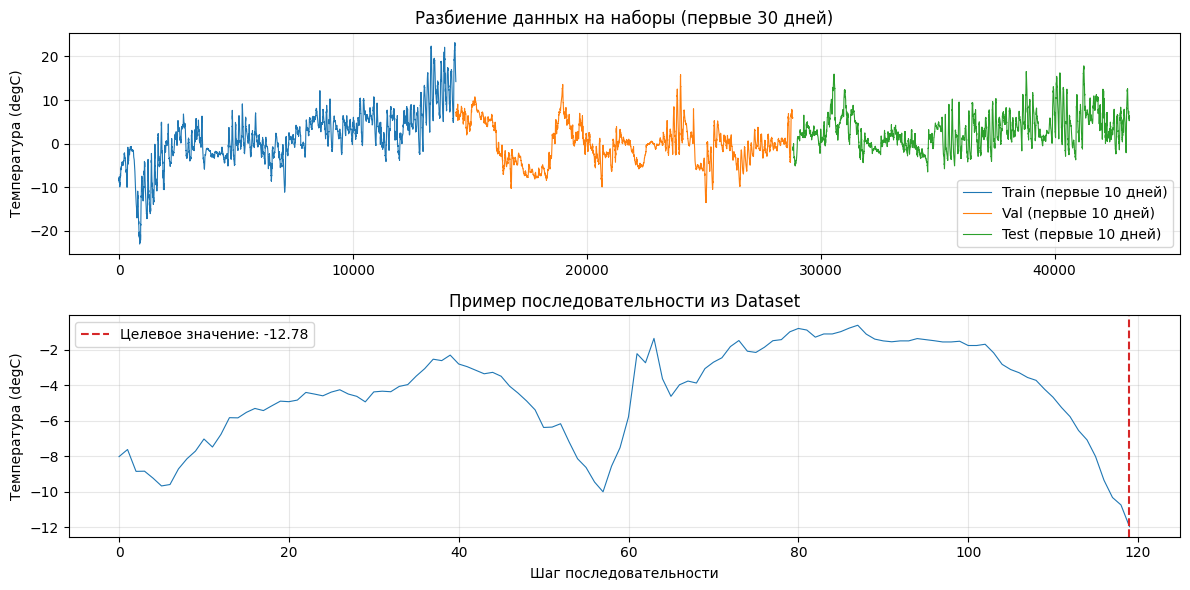

In [24]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6))

train_temperatures = temperature[:num_train_samples]
val_temperatures = temperature[num_train_samples:num_train_samples + num_val_samples]
test_temperatures = temperature[num_train_samples + num_val_samples:]

axes[0].plot(train_temperatures[:14400], color='tab:blue', label='Train (первые 10 дней)', linewidth=0.8)
axes[0].plot(range(14400, 14400 + len(val_temperatures[:14400])), val_temperatures[:14400], color='tab:orange', label='Val (первые 10 дней)', linewidth=0.8)
axes[0].plot(range(14400 + len(val_temperatures[:14400]), 14400 + len(val_temperatures[:14400]) + len(test_temperatures[:14400])), test_temperatures[:14400], color='tab:green', label='Test (первые 10 дней)', linewidth=0.8)
axes[0].set_title('Разбиение данных на наборы (первые 30 дней)')
axes[0].set_ylabel('Температура (degC)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

sample_idx = 0
sample_x, sample_y = train_dataset[sample_idx]
axes[1].plot(sample_x.numpy()[:, 1] * std[1] + mean[1], color='tab:blue', linewidth=0.8)
axes[1].axvline(x=len(sample_x) - 1, color='tab:red', linestyle='--', label=f'Целевое значение: {sample_y.item() * std[1] + mean[1]:.2f}')
axes[1].set_title('Пример последовательности из Dataset')
axes[1].set_ylabel('Температура (degC)')
axes[1].set_xlabel('Шаг последовательности')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [25]:
train_dataset[0]

(tensor([[ 0.9137, -1.9206, -1.9745,  ..., -0.7302, -0.7794, -0.2812],
         [ 0.9113, -1.8750, -1.9282,  ..., -1.2844, -1.2615, -0.1158],
         [ 0.9266, -2.0153, -2.0681,  ..., -1.2975, -1.3174, -0.2113],
         ...,
         [ 0.9207, -2.1829, -2.2339,  ...,  0.4175,  0.3528, -1.8870],
         [ 0.9748, -2.2308, -2.2858,  ...,  0.3849,  0.0816, -1.7889],
         [ 1.0195, -2.3698, -2.4268,  ..., -0.0194, -0.0777, -2.0229]]),
 tensor(-2.4633))

In [26]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

In [27]:
for samples, targets in train_loader:
    print("Размерность обучающей мини-выборки:", samples.shape)
    print("Размерность целевой переменной:", targets.shape)
    break

Размерность обучающей мини-выборки: torch.Size([256, 120, 14])
Размерность целевой переменной: torch.Size([256])


## Создаем базовое решение

Всегда предсказываем последнее значение

In [28]:
def evaluate_naive_method(dataset):
    total_abs_err = 0.0
    samples_seen = 0
    for samples, targets in dataset:
        samples = samples.numpy() if isinstance(samples, torch.Tensor) else samples
        targets = targets.numpy() if isinstance(targets, torch.Tensor) else targets
        # "Наивный" прогноз — последнее значение температуры в окне (нормированное).
        preds = samples[:, -1, 1]
        # MAE в нормированных единицах, затем перевод в °C (× std[1]).
        total_abs_err += np.sum(np.abs(preds - targets)) * std[1]
        samples_seen += samples.shape[0]
    return total_abs_err / samples_seen

print(f"Validation MAE: {evaluate_naive_method(val_loader):.2f}")
print(f"Test MAE: {evaluate_naive_method(test_loader):.2f}")

Validation MAE: 0.68
Test MAE: 0.72


## Полносвязная нейронная сеть

In [29]:
class DenseModel(nn.Module):
    def __init__(self, input_dim):
        super(DenseModel, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(input_dim * sequence_length, 16)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(16, 1)
        
    def forward(self, x):
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x.squeeze(-1)

In [30]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [31]:
def train_model(model, train_loader, val_loader, epochs=10, lr=0.001):
    model = model.to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    
    history = {'train_mae': [], 'val_mae': []}
    best_val_mae = float('inf')
    best_model_state = None
    
    for epoch in range(epochs):
        model.train()
        train_loss = 0
        train_mae = 0
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            output = model(batch_x)
            loss = criterion(output, batch_y)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * batch_x.size(0)
            train_mae += torch.sum(torch.abs(output - batch_y)).item()
        
        model.eval()
        val_loss = 0
        val_mae = 0
        with torch.no_grad():
            for batch_x, batch_y in val_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                output = model(batch_x)
                val_loss += criterion(output, batch_y).item() * batch_x.size(0)
                val_mae += torch.sum(torch.abs(output - batch_y)).item()
        
        # MAE считается на нормированной цели — приводим к °C
        train_mae = train_mae / len(train_loader.dataset) * std[1]
        val_mae = val_mae / len(val_loader.dataset) * std[1]
        
        history['train_mae'].append(train_mae)
        history['val_mae'].append(val_mae)
        
        print(f"Epoch {epoch+1}/{epochs} - Train MAE: {train_mae:.4f} degC - Val MAE: {val_mae:.4f} degC")
        
        if val_mae < best_val_mae:
            best_val_mae = val_mae
            best_model_state = model.state_dict().copy()
    
    if best_model_state is not None:
        model.load_state_dict(best_model_state)
    
    return model, history

In [32]:
model_dense = DenseModel(raw_data.shape[-1])
model_dense, history_dense = train_model(model_dense, train_loader, val_loader, epochs=10)

Epoch 1/10 - Train MAE: 1.8290 degC - Val MAE: 1.1339 degC
Epoch 2/10 - Train MAE: 0.9773 degC - Val MAE: 0.8771 degC
Epoch 3/10 - Train MAE: 0.8146 degC - Val MAE: 0.7857 degC
Epoch 4/10 - Train MAE: 0.7641 degC - Val MAE: 0.7422 degC
Epoch 5/10 - Train MAE: 0.7268 degC - Val MAE: 0.8059 degC
Epoch 6/10 - Train MAE: 0.6887 degC - Val MAE: 0.7618 degC
Epoch 7/10 - Train MAE: 0.6766 degC - Val MAE: 0.7414 degC
Epoch 8/10 - Train MAE: 0.6701 degC - Val MAE: 0.6581 degC
Epoch 9/10 - Train MAE: 0.6616 degC - Val MAE: 0.6710 degC
Epoch 10/10 - Train MAE: 0.6423 degC - Val MAE: 0.6492 degC


In [33]:
def evaluate_model(model, test_loader):
    model.eval()
    total_mae = 0
    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            output = model(batch_x)
            total_mae += torch.sum(torch.abs(output - batch_y)).item()
    # MAE на нормированной цели → °C
    return total_mae / len(test_loader.dataset) * std[1]

print(f"Test MAE: {evaluate_model(model_dense, test_loader):.2f} degC")

Test MAE: 0.68 degC


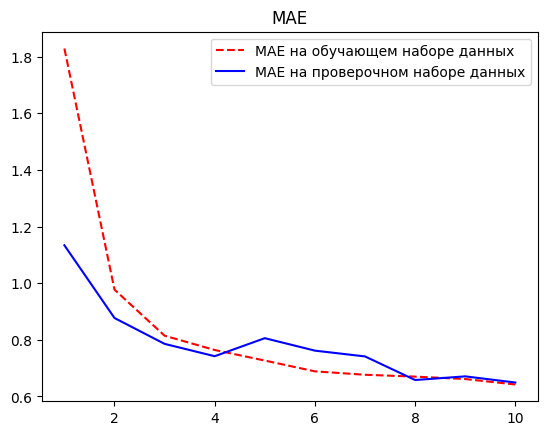

In [34]:
loss = history_dense['train_mae']
val_loss = history_dense['val_mae']
epochs = range(1, len(loss) + 1)
plt.figure()
plt.plot(epochs, loss, "r--", label="MAE на обучающем наборе данных")
plt.plot(epochs, val_loss, "b", label="MAE на проверочном наборе данных")
plt.title("MAE")
plt.legend()
plt.show()

## Одномерная сверточная нейронная сеть

In [35]:
class Conv1DModel(nn.Module):
    def __init__(self, input_dim):
        super(Conv1DModel, self).__init__()
        self.conv1 = nn.Conv1d(input_dim, 8, kernel_size=24)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool1d(2)
        self.conv2 = nn.Conv1d(8, 8, kernel_size=12)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool1d(2)
        self.conv3 = nn.Conv1d(8, 8, kernel_size=6)
        self.relu3 = nn.ReLU()
        self.global_pool = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Linear(8, 1)
        
    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.relu3(self.conv3(x))
        x = self.global_pool(x).squeeze(-1)
        x = self.fc(x).squeeze(-1)
        return x

In [36]:
model_conv = Conv1DModel(raw_data.shape[-1])
model_conv, history_conv = train_model(model_conv, train_loader, val_loader, epochs=10)

Epoch 1/10 - Train MAE: 3.9356 degC - Val MAE: 3.1450 degC
Epoch 2/10 - Train MAE: 3.1718 degC - Val MAE: 2.7369 degC
Epoch 3/10 - Train MAE: 2.7861 degC - Val MAE: 2.6308 degC
Epoch 4/10 - Train MAE: 2.6199 degC - Val MAE: 2.6501 degC
Epoch 5/10 - Train MAE: 2.5534 degC - Val MAE: 2.4118 degC
Epoch 6/10 - Train MAE: 2.4696 degC - Val MAE: 2.3790 degC
Epoch 7/10 - Train MAE: 2.4331 degC - Val MAE: 2.3495 degC
Epoch 8/10 - Train MAE: 2.3615 degC - Val MAE: 2.2938 degC
Epoch 9/10 - Train MAE: 2.3065 degC - Val MAE: 2.2633 degC
Epoch 10/10 - Train MAE: 2.2616 degC - Val MAE: 2.2209 degC


In [37]:
print(f"MAE на тестовом наборе данных: {evaluate_model(model_conv, test_loader):.2f} degC")

MAE на тестовом наборе данных: 2.33 degC


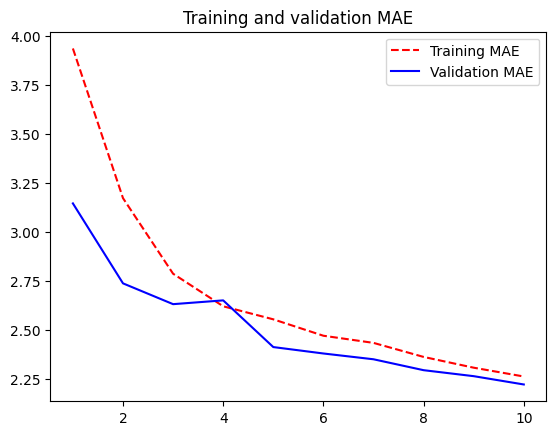

In [38]:
loss = history_conv['train_mae']
val_loss = history_conv['val_mae']
epochs = range(1, len(loss) + 1)
plt.figure()
plt.plot(epochs, loss, "r--", label="Training MAE")
plt.plot(epochs, val_loss, "b", label="Validation MAE")
plt.title("Training and validation MAE")
plt.legend()
plt.show()

## Сеть LSTM

In [39]:
class LSTMModel(nn.Module):
    def __init__(self, input_dim, hidden_dim=16):
        super(LSTMModel, self).__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)
        
    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        out = self.fc(lstm_out[:, -1, :])
        return out.squeeze(-1)

In [41]:
model_lstm = LSTMModel(raw_data.shape[-1])
model_lstm, history_lstm = train_model(model_lstm, train_loader, val_loader, epochs=10)

Epoch 1/10 - Train MAE: 3.1133 degC - Val MAE: 1.3964 degC
Epoch 2/10 - Train MAE: 1.1853 degC - Val MAE: 0.8824 degC
Epoch 3/10 - Train MAE: 0.8470 degC - Val MAE: 0.7126 degC
Epoch 4/10 - Train MAE: 0.7173 degC - Val MAE: 0.6435 degC
Epoch 5/10 - Train MAE: 0.6537 degC - Val MAE: 0.5929 degC
Epoch 6/10 - Train MAE: 0.6175 degC - Val MAE: 0.5688 degC
Epoch 7/10 - Train MAE: 0.5932 degC - Val MAE: 0.5532 degC
Epoch 8/10 - Train MAE: 0.5762 degC - Val MAE: 0.5355 degC
Epoch 9/10 - Train MAE: 0.5655 degC - Val MAE: 0.5315 degC
Epoch 10/10 - Train MAE: 0.5560 degC - Val MAE: 0.5288 degC


In [42]:
print(f"MAE на тестовом наборе данных: {evaluate_model(model_lstm, test_loader):.2f} degC")

MAE на тестовом наборе данных: 0.55 degC


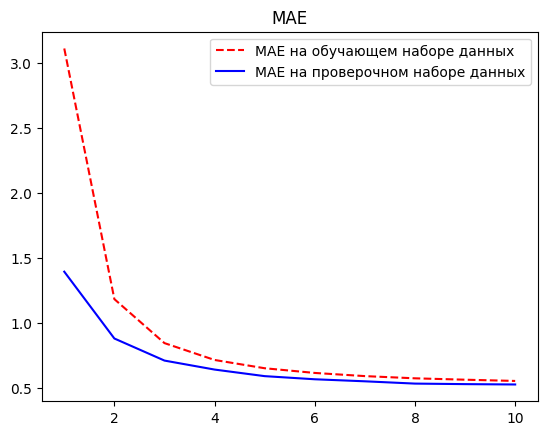

In [43]:
loss = history_lstm['train_mae']
val_loss = history_lstm['val_mae']
epochs = range(1, len(loss) + 1)
plt.figure()
plt.plot(epochs, loss, "r--", label="MAE на обучающем наборе данных")
plt.plot(epochs, val_loss, "b", label="MAE на проверочном наборе данных")
plt.title("MAE")
plt.legend()
plt.show()

Используем Dropout для снижения переобучения

In [44]:
class LSTMWithDropout(nn.Module):
    def __init__(self, input_dim, hidden_dim=32, dropout=0.25):
        super(LSTMWithDropout, self).__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, batch_first=True, dropout=dropout)
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(hidden_dim, 1)
        
    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        out = self.dropout(lstm_out[:, -1, :])
        out = self.fc(out)
        return out.squeeze(-1)

In [45]:
model_lstm_dropout = LSTMWithDropout(raw_data.shape[-1])
model_lstm_dropout, history_lstm_dropout = train_model(model_lstm_dropout, train_loader, val_loader, epochs=20)

/home/reshetnikov/miniconda3/envs/mmyolo/lib/python3.8/site-packages/torch/nn/modules/rnn.py:82: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.25 and num_layers=1
  warnings.warn("dropout option adds dropout after all but last "


Epoch 1/20 - Train MAE: 2.7423 degC - Val MAE: 1.0656 degC
Epoch 2/20 - Train MAE: 1.6447 degC - Val MAE: 0.8173 degC
Epoch 3/20 - Train MAE: 1.4705 degC - Val MAE: 0.7075 degC
Epoch 4/20 - Train MAE: 1.3860 degC - Val MAE: 0.6686 degC
Epoch 5/20 - Train MAE: 1.3424 degC - Val MAE: 0.6411 degC
Epoch 6/20 - Train MAE: 1.3022 degC - Val MAE: 0.6322 degC
Epoch 7/20 - Train MAE: 1.2879 degC - Val MAE: 0.6473 degC
Epoch 8/20 - Train MAE: 1.2638 degC - Val MAE: 0.5940 degC
Epoch 9/20 - Train MAE: 1.2509 degC - Val MAE: 0.6458 degC
Epoch 10/20 - Train MAE: 1.2521 degC - Val MAE: 0.6075 degC
Epoch 11/20 - Train MAE: 1.2440 degC - Val MAE: 0.6005 degC
Epoch 12/20 - Train MAE: 1.2425 degC - Val MAE: 0.5861 degC
Epoch 13/20 - Train MAE: 1.2387 degC - Val MAE: 0.6108 degC
Epoch 14/20 - Train MAE: 1.2414 degC - Val MAE: 0.5303 degC
Epoch 15/20 - Train MAE: 1.2331 degC - Val MAE: 0.5860 degC
Epoch 16/20 - Train MAE: 1.2239 degC - Val MAE: 0.5099 degC
Epoch 17/20 - Train MAE: 1.2396 degC - Val MAE: 0

In [46]:
print(f"MAE на тестовом наборе данных: {evaluate_model(model_lstm_dropout, test_loader):.2f} degC")

MAE на тестовом наборе данных: 0.58 degC


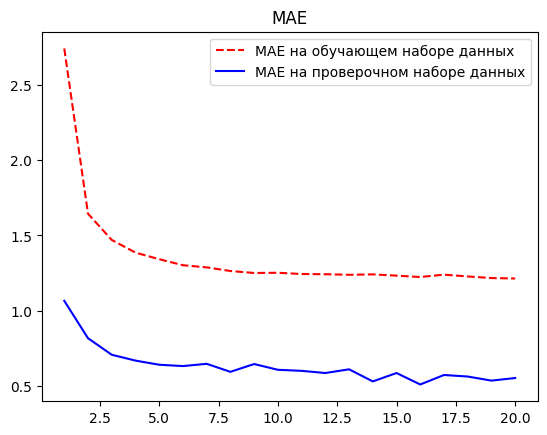

In [47]:
loss = history_lstm_dropout['train_mae']
val_loss = history_lstm_dropout['val_mae']
epochs = range(1, len(loss) + 1)
plt.figure()
plt.plot(epochs, loss, "r--", label="MAE на обучающем наборе данных")
plt.plot(epochs, val_loss, "b", label="MAE на проверочном наборе данных")
plt.title("MAE")
plt.legend()
plt.show()

In [48]:
t=next(iter(test_loader))
t[0].shape

torch.Size([256, 120, 14])

In [49]:
s = test_loader.dataset[0]
print(s[0].size(), s[1].size())
model_lstm_dropout(t.unsqueeze(0))

torch.Size([120, 14]) torch.Size([])


AttributeError: 'list' object has no attribute 'unsqueeze'

## Несколько рекуррентных слоев

In [50]:
class StackedGRU(nn.Module):
    def __init__(self, input_dim, hidden_dim=32, dropout=0.5):
        super(StackedGRU, self).__init__()
        self.gru1 = nn.GRU(input_dim, hidden_dim, batch_first=True, dropout=dropout)
        self.gru2 = nn.GRU(hidden_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, 1)
        
    def forward(self, x):
        out, _ = self.gru1(x)
        out, _ = self.gru2(out)
        out = self.dropout(out[:, -1, :])
        out = self.fc(out)
        return out.squeeze(-1)

In [51]:
model_stacked_gru = StackedGRU(raw_data.shape[-1])
model_stacked_gru, history_stacked_gru = train_model(model_stacked_gru, train_loader, val_loader, epochs=20)

/home/reshetnikov/miniconda3/envs/mmyolo/lib/python3.8/site-packages/torch/nn/modules/rnn.py:82: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.5 and num_layers=1
  warnings.warn("dropout option adds dropout after all but last "


Epoch 1/20 - Train MAE: 2.5126 degC - Val MAE: 0.9191 degC
Epoch 2/20 - Train MAE: 1.5073 degC - Val MAE: 0.6897 degC
Epoch 3/20 - Train MAE: 1.3422 degC - Val MAE: 0.8279 degC
Epoch 4/20 - Train MAE: 1.2884 degC - Val MAE: 0.5920 degC
Epoch 5/20 - Train MAE: 1.2482 degC - Val MAE: 0.5930 degC
Epoch 6/20 - Train MAE: 1.2437 degC - Val MAE: 0.6165 degC
Epoch 7/20 - Train MAE: 1.2314 degC - Val MAE: 0.5943 degC
Epoch 8/20 - Train MAE: 1.2278 degC - Val MAE: 0.6409 degC
Epoch 9/20 - Train MAE: 1.2189 degC - Val MAE: 0.6105 degC
Epoch 10/20 - Train MAE: 1.2180 degC - Val MAE: 0.6156 degC
Epoch 11/20 - Train MAE: 1.2193 degC - Val MAE: 0.5200 degC
Epoch 12/20 - Train MAE: 1.2191 degC - Val MAE: 0.5173 degC
Epoch 13/20 - Train MAE: 1.2041 degC - Val MAE: 0.6091 degC
Epoch 14/20 - Train MAE: 1.2127 degC - Val MAE: 0.5876 degC
Epoch 15/20 - Train MAE: 1.2230 degC - Val MAE: 0.5702 degC
Epoch 16/20 - Train MAE: 1.2132 degC - Val MAE: 0.5305 degC
Epoch 17/20 - Train MAE: 1.2042 degC - Val MAE: 0

In [52]:
print(f"MAE на тестовом наборе данных: {evaluate_model(model_stacked_gru, test_loader):.2f} degC")

MAE на тестовом наборе данных: 0.57 degC


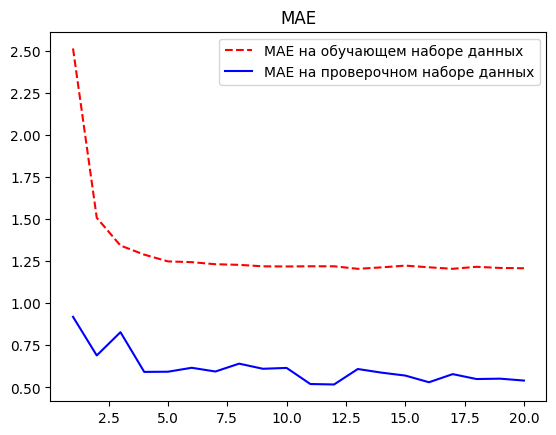

In [53]:
loss = history_stacked_gru['train_mae']
val_loss = history_stacked_gru['val_mae']
epochs = range(1, len(loss) + 1)
plt.figure()
plt.plot(epochs, loss, "r--", label="MAE на обучающем наборе данных")
plt.plot(epochs, val_loss, "b", label="MAE на проверочном наборе данных")
plt.title("MAE")
plt.legend()
plt.show()

## Используем двунаправленную рекуррентную сеть

In [54]:
class BidirectionalLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim=16):
        super(BidirectionalLSTM, self).__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden_dim * 2, 1)
        
    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        out = self.fc(lstm_out[:, -1, :])
        return out.squeeze(-1)

In [55]:
model_bilstm = BidirectionalLSTM(raw_data.shape[-1])
model_bilstm, history_bilstm = train_model(model_bilstm, train_loader, val_loader, epochs=10)

Epoch 1/10 - Train MAE: 2.9627 degC - Val MAE: 1.1021 degC
Epoch 2/10 - Train MAE: 0.9867 degC - Val MAE: 0.7896 degC
Epoch 3/10 - Train MAE: 0.7750 degC - Val MAE: 0.6671 degC
Epoch 4/10 - Train MAE: 0.6866 degC - Val MAE: 0.6117 degC
Epoch 5/10 - Train MAE: 0.6401 degC - Val MAE: 0.5875 degC
Epoch 6/10 - Train MAE: 0.6129 degC - Val MAE: 0.5691 degC
Epoch 7/10 - Train MAE: 0.5942 degC - Val MAE: 0.5511 degC
Epoch 8/10 - Train MAE: 0.5805 degC - Val MAE: 0.5446 degC
Epoch 9/10 - Train MAE: 0.5712 degC - Val MAE: 0.5343 degC
Epoch 10/10 - Train MAE: 0.5614 degC - Val MAE: 0.5299 degC


In [56]:
print(f"MAE на тестовом наборе данных: {evaluate_model(model_bilstm, test_loader):.2f} degC")

MAE на тестовом наборе данных: 0.55 degC


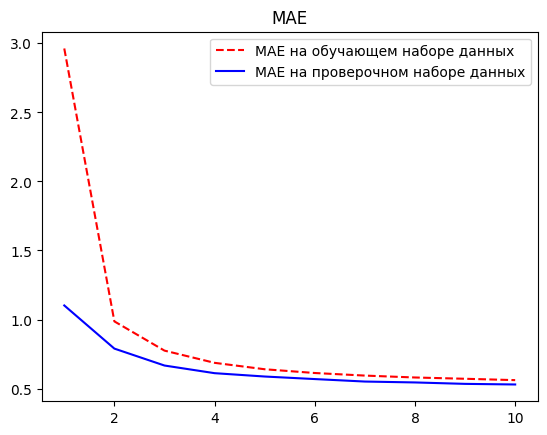

In [57]:
loss = history_bilstm['train_mae']
val_loss = history_bilstm['val_mae']
epochs = range(1, len(loss) + 1)
plt.figure()
plt.plot(epochs, loss, "r--", label="MAE на обучающем наборе данных")
plt.plot(epochs, val_loss, "b", label="MAE на проверочном наборе данных")
plt.title("MAE")
plt.legend()
plt.show()

## Примеры предсказаний

In [58]:
def get_predictions(model, dataset, num_samples=100):
    model.eval()
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for i in range(min(num_samples, len(dataset))):
            sample_x, sample_y = dataset[i]
            sample_x = sample_x.unsqueeze(0).to(device)
            pred = model(sample_x).item()
            # денормируем прогноз и цель в °C
            all_preds.append(pred * std[1] + mean[1])
            y = sample_y.item() if isinstance(sample_y, torch.Tensor) else sample_y
            all_targets.append(y * std[1] + mean[1])
    
    return np.array(all_preds), np.array(all_targets)

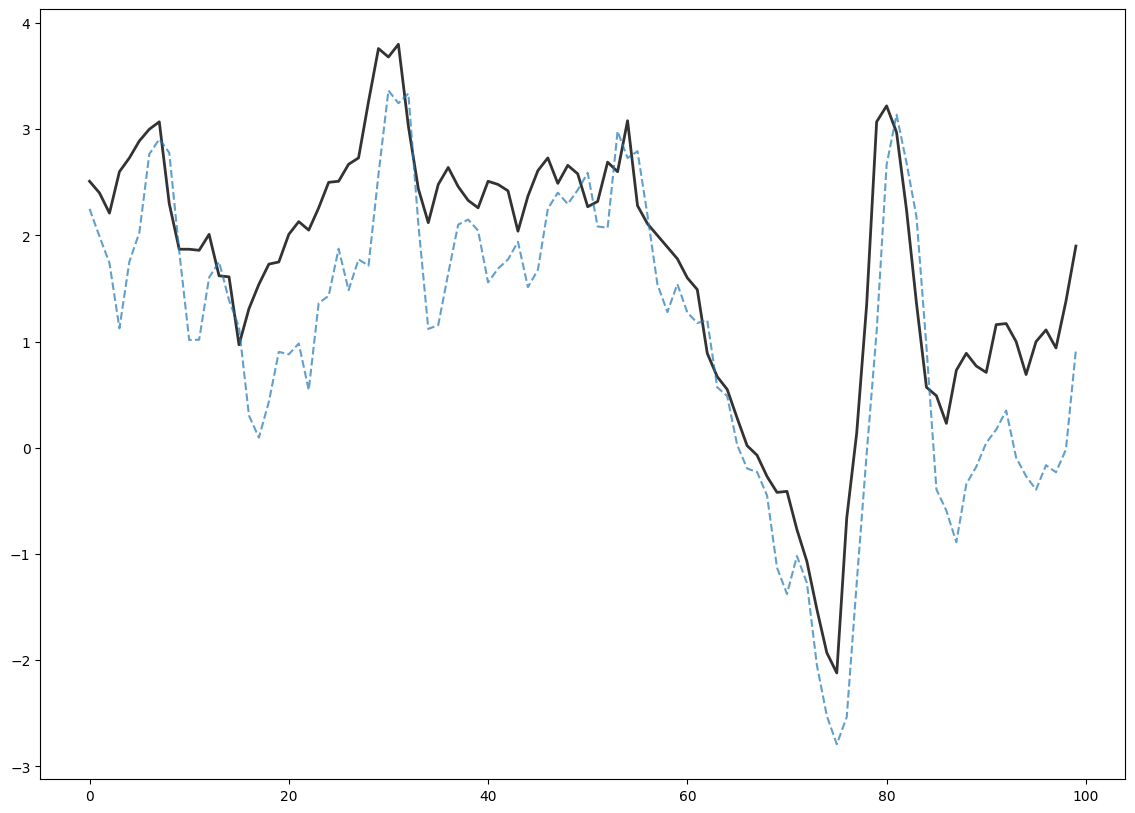

In [59]:
num_examples = 100
fig, axes = plt.subplots(1, 1, figsize=(14, 10))
preds_dense, targets_dense = get_predictions(model_dense, test_dataset, num_examples)
axes.plot(targets_dense, label='Фактические значения', color='black', linewidth=2, alpha=0.8)
axes.plot(preds_dense, label='Dense', linestyle='--', alpha=0.7)

In [60]:

preds_conv, targets_conv = get_predictions(model_conv, test_dataset, num_examples)
preds_lstm, targets_lstm = get_predictions(model_lstm, test_dataset, num_examples)
preds_lstm_dropout, targets_lstm_dropout = get_predictions(model_lstm_dropout, test_dataset, num_examples)
preds_stacked_gru, targets_stacked_gru = get_predictions(model_stacked_gru, test_dataset, num_examples)
preds_bilstm, targets_bilstm = get_predictions(model_bilstm, test_dataset, num_examples)

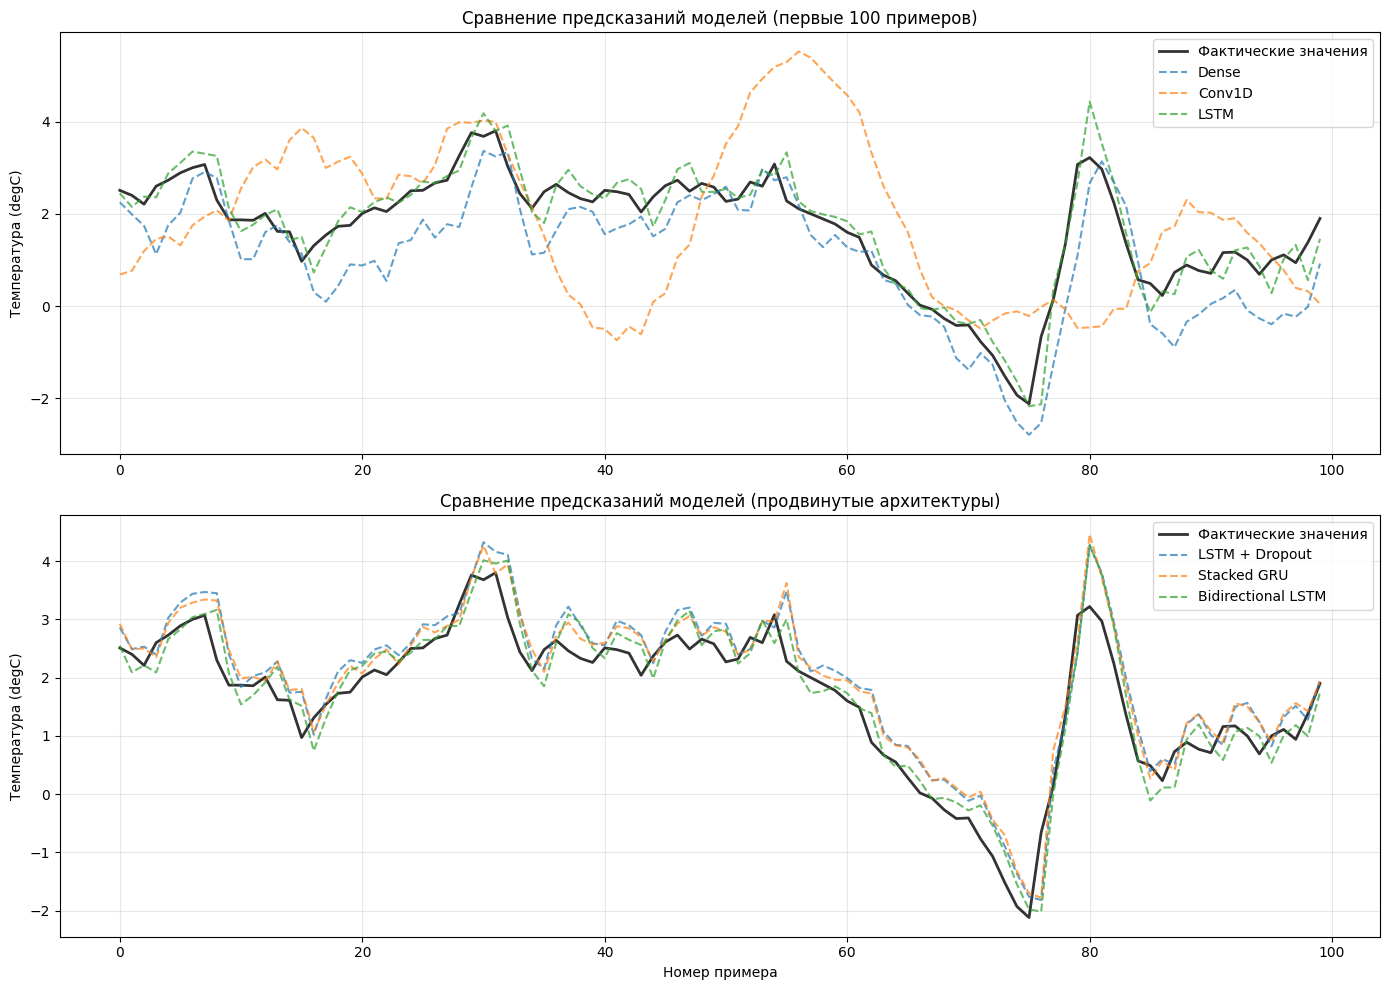

In [61]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

axes[0].plot(targets_dense, label='Фактические значения', color='black', linewidth=2, alpha=0.8)
axes[0].plot(preds_dense, label='Dense', linestyle='--', alpha=0.7)
axes[0].plot(preds_conv, label='Conv1D', linestyle='--', alpha=0.7)
axes[0].plot(preds_lstm, label='LSTM', linestyle='--', alpha=0.7)
axes[0].set_title('Сравнение предсказаний моделей (первые 100 примеров)')
axes[0].set_ylabel('Температура (degC)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(targets_lstm_dropout, label='Фактические значения', color='black', linewidth=2, alpha=0.8)
axes[1].plot(preds_lstm_dropout, label='LSTM + Dropout', linestyle='--', alpha=0.7)
axes[1].plot(preds_stacked_gru, label='Stacked GRU', linestyle='--', alpha=0.7)
axes[1].plot(preds_bilstm, label='Bidirectional LSTM', linestyle='--', alpha=0.7)
axes[1].set_title('Сравнение предсказаний моделей (продвинутые архитектуры)')
axes[1].set_xlabel('Номер примера')
axes[1].set_ylabel('Температура (degC)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

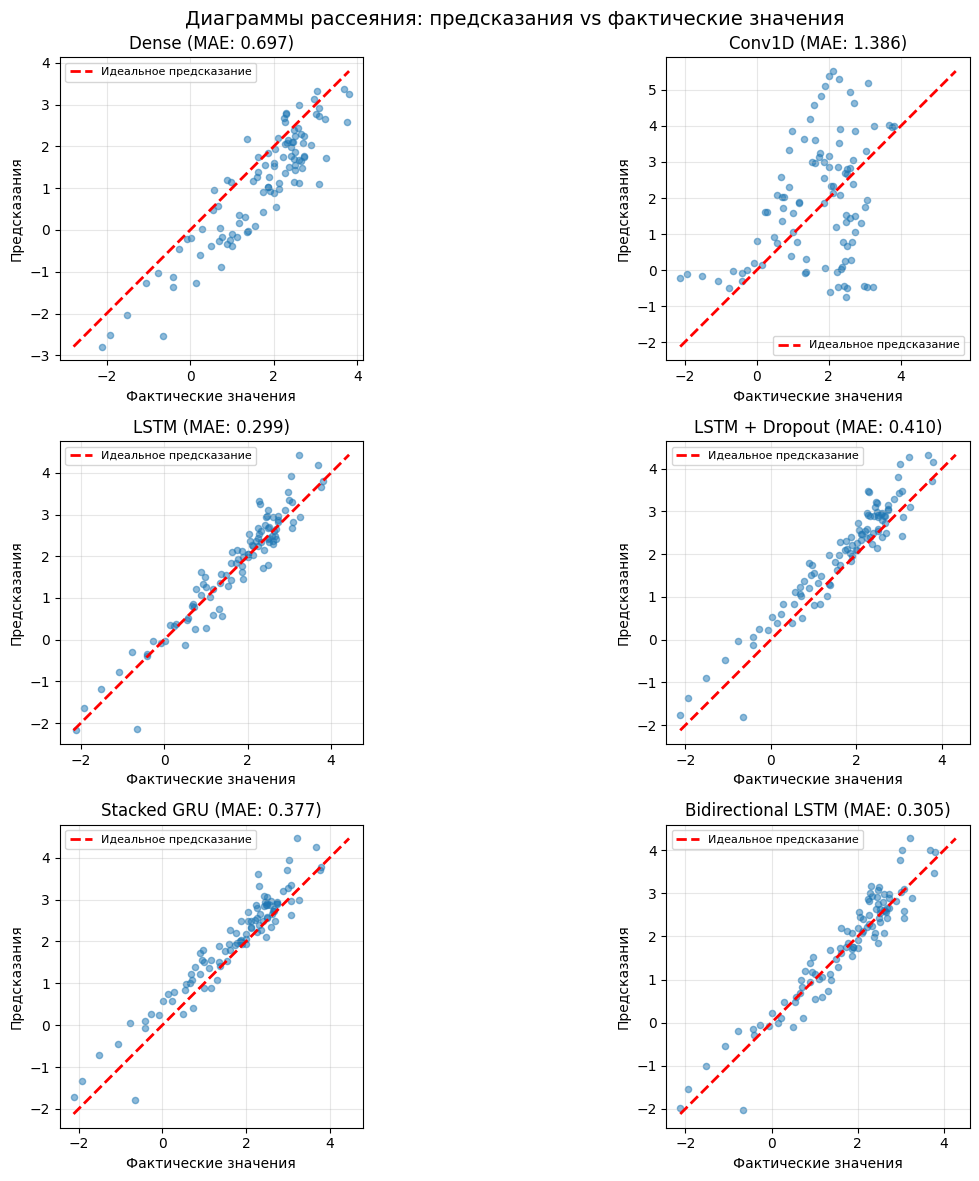

In [62]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))

models_data = [
    ('Dense', preds_dense, targets_dense),
    ('Conv1D', preds_conv, targets_conv),
    ('LSTM', preds_lstm, targets_lstm),
    ('LSTM + Dropout', preds_lstm_dropout, targets_lstm_dropout),
    ('Stacked GRU', preds_stacked_gru, targets_stacked_gru),
    ('Bidirectional LSTM', preds_bilstm, targets_bilstm)
]

for ax, (name, preds, targets) in zip(axes.flat, models_data):
    ax.scatter(targets, preds, alpha=0.5, s=20)
    
    min_val = min(targets.min(), preds.min())
    max_val = max(targets.max(), preds.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Идеальное предсказание')
    
    mae = np.mean(np.abs(preds - targets))
    ax.set_title(f'{name} (MAE: {mae:.3f})')
    ax.set_xlabel('Фактические значения')
    ax.set_ylabel('Предсказания')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_aspect('equal')

plt.suptitle('Диаграммы рассеяния: предсказания vs фактические значения', fontsize=14)
plt.tight_layout()
plt.show()

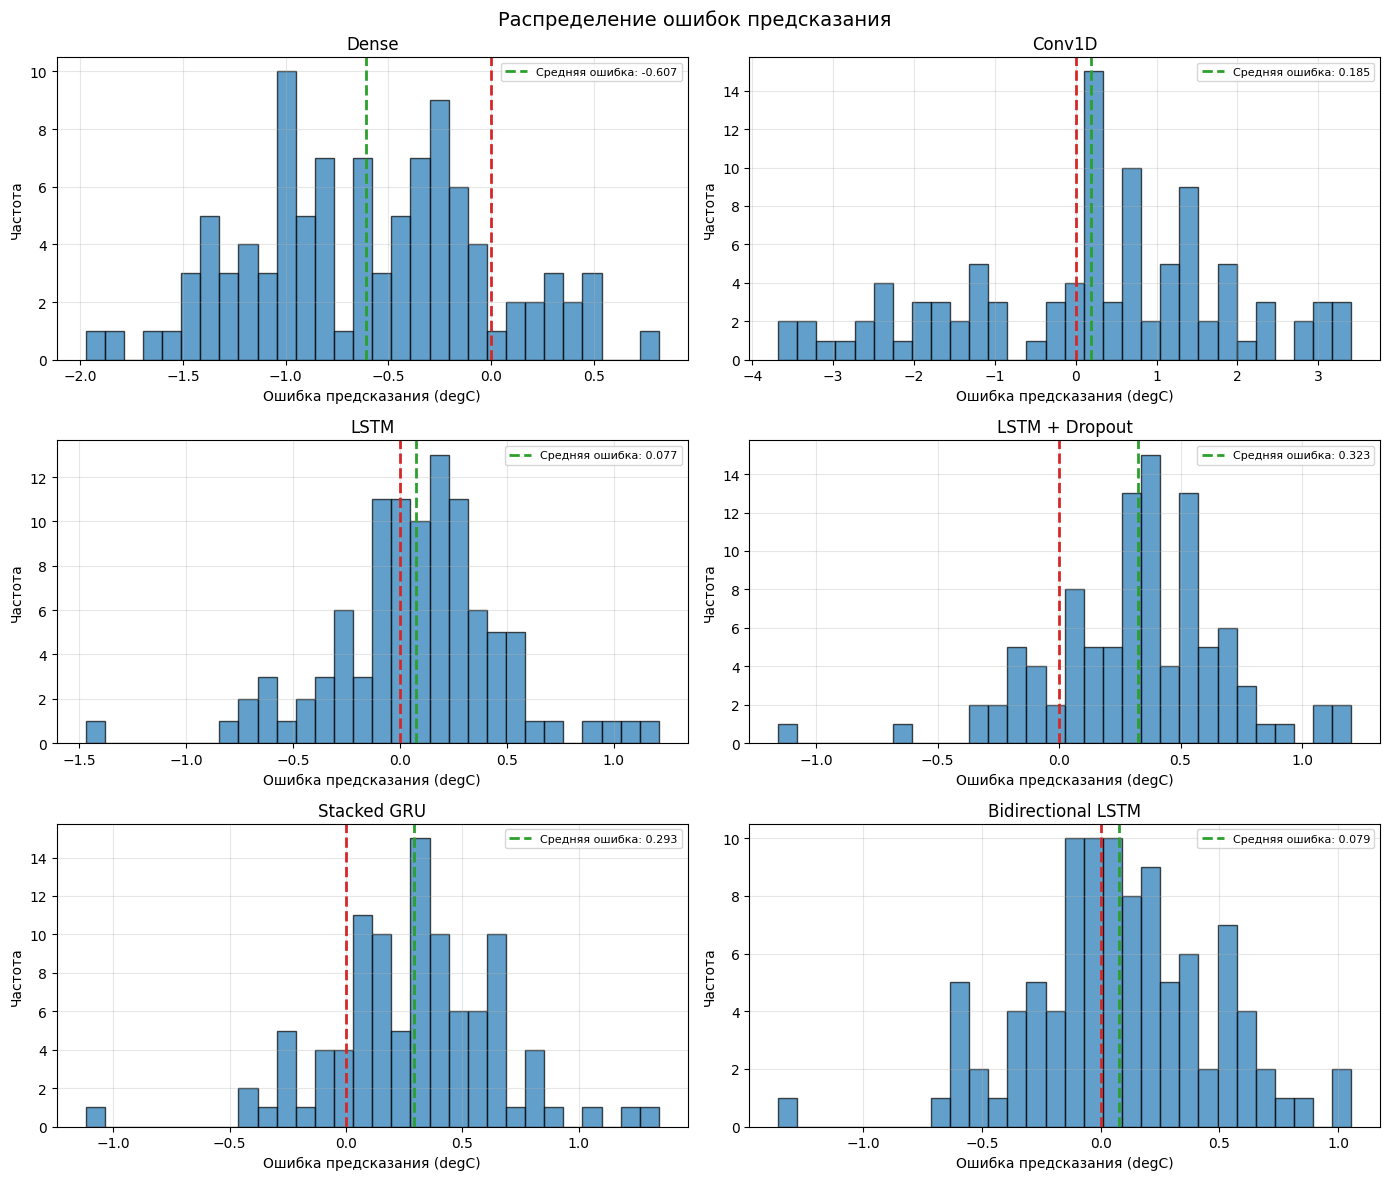

In [63]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for ax, (name, preds, targets) in zip(axes.flat, models_data):
    errors = preds - targets
    ax.hist(errors, bins=30, color='tab:blue', alpha=0.7, edgecolor='black')
    ax.axvline(x=0, color='tab:red', linestyle='--', linewidth=2)
    ax.axvline(x=np.mean(errors), color='tab:green', linestyle='--', linewidth=2, 
               label=f'Средняя ошибка: {np.mean(errors):.3f}')
    ax.set_title(f'{name}')
    ax.set_xlabel('Ошибка предсказания (degC)')
    ax.set_ylabel('Частота')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle('Распределение ошибок предсказания', fontsize=14)
plt.tight_layout()
plt.show()

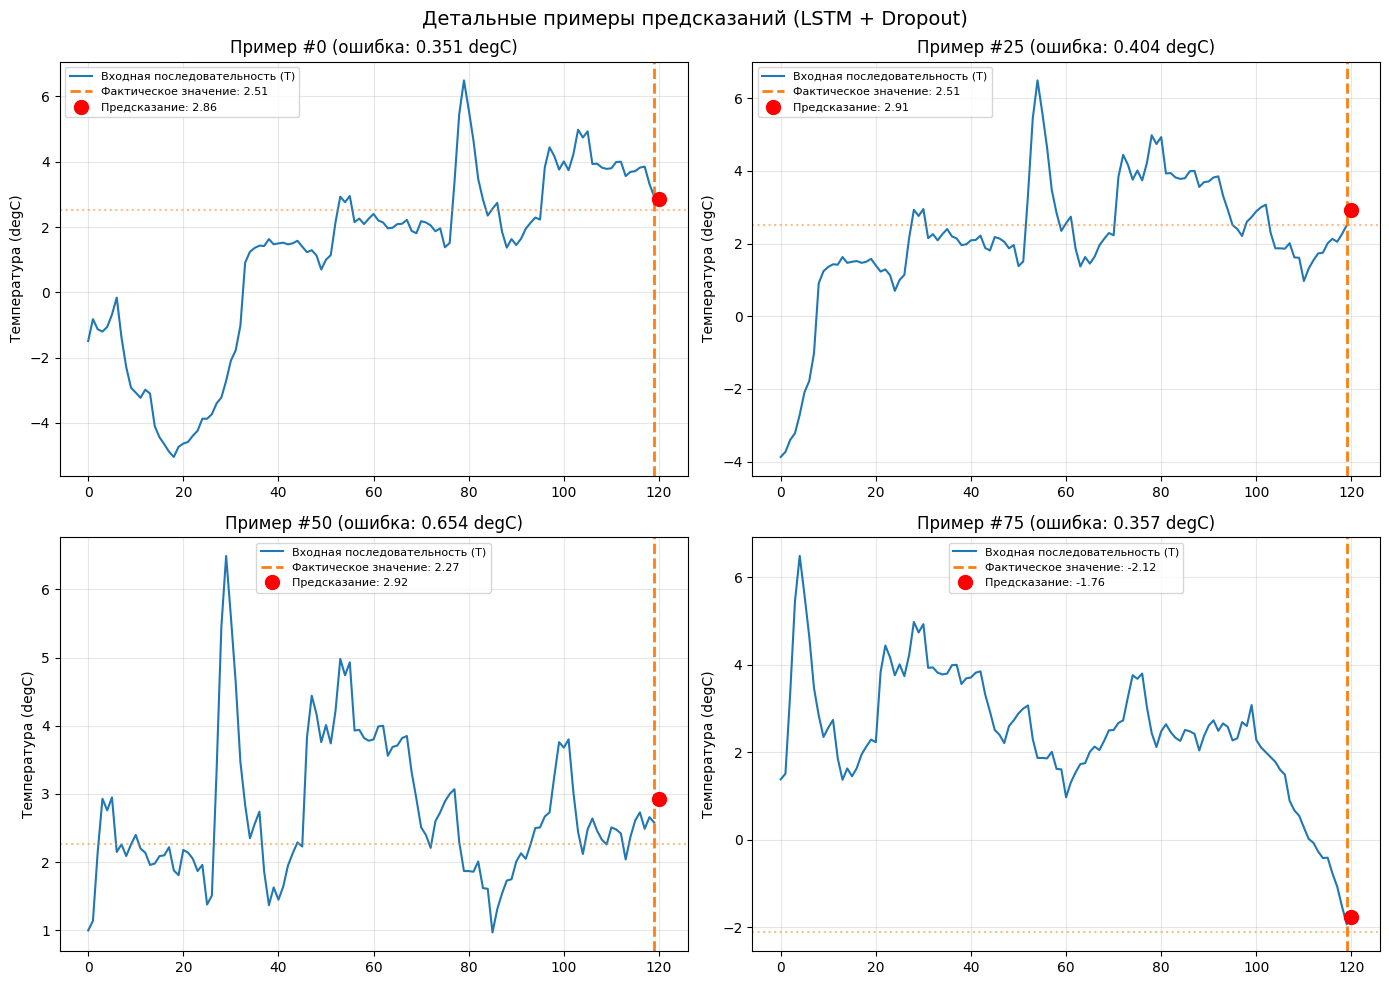

In [64]:
sample_indices = [0, 25, 50, 75]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, idx in zip(axes.flat, sample_indices):
    sample_x, sample_y = test_dataset[idx]
    sample_x = sample_x.numpy()
    
    # окно в нормированных единицах — денормируем в °C
    ax.plot(sample_x[:, 1] * std[1] + mean[1], color='tab:blue', linewidth=1.5, label='Входная последовательность (T)')
    
    best_pred = preds_lstm_dropout[idx]
    best_target = targets_lstm_dropout[idx]
    
    ax.axvline(x=len(sample_x) - 1, color='tab:orange', linestyle='--', linewidth=2, 
               label=f'Фактическое значение: {best_target:.2f}')
    ax.axhline(y=best_target, color='tab:orange', linestyle=':', alpha=0.5)
    
    ax.plot(len(sample_x), best_pred, 'ro', markersize=10, 
            label=f'Предсказание: {best_pred:.2f}')
    
    error = abs(best_pred - best_target)
    ax.set_title(f'Пример #{idx} (ошибка: {error:.3f} degC)')
    ax.set_ylabel('Температура (degC)')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle('Детальные примеры предсказаний (LSTM + Dropout)', fontsize=14)
plt.tight_layout()
plt.show()

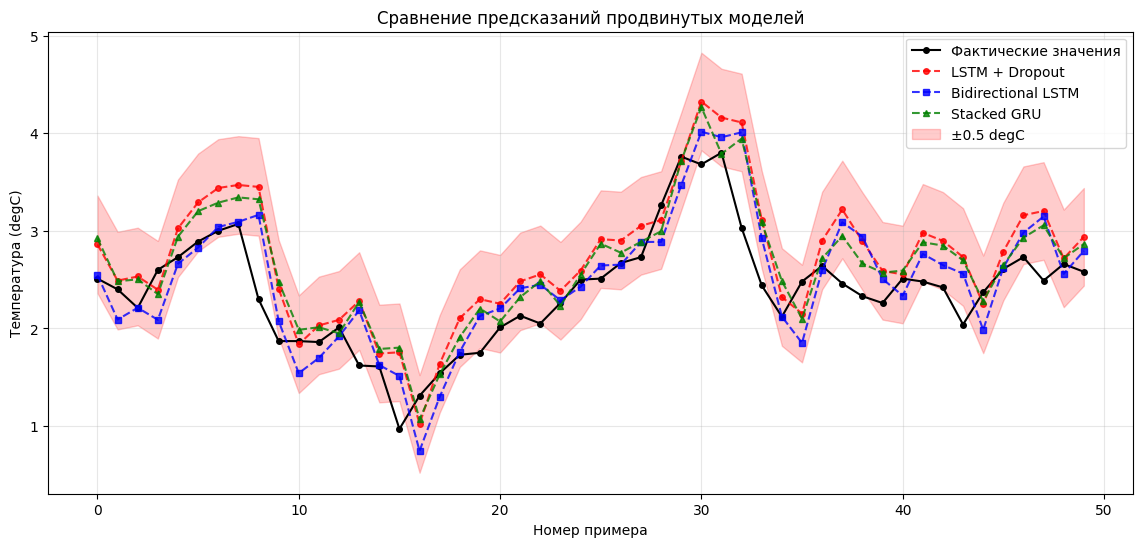

In [65]:
plt.figure(figsize=(14, 6))

window = 50
start_idx = 0

plt.plot(range(window), targets_lstm_dropout[start_idx:start_idx+window], 
         'ko-', label='Фактические значения', markersize=4, linewidth=1.5)
plt.plot(range(window), preds_lstm_dropout[start_idx:start_idx+window], 
         'r--o', label='LSTM + Dropout', markersize=4, linewidth=1.5, alpha=0.8)
plt.plot(range(window), preds_bilstm[start_idx:start_idx+window], 
         'b--s', label='Bidirectional LSTM', markersize=4, linewidth=1.5, alpha=0.8)
plt.plot(range(window), preds_stacked_gru[start_idx:start_idx+window], 
         'g--^', label='Stacked GRU', markersize=4, linewidth=1.5, alpha=0.8)

plt.fill_between(range(window), 
                 preds_lstm_dropout[start_idx:start_idx+window] - 0.5,
                 preds_lstm_dropout[start_idx:start_idx+window] + 0.5,
                 alpha=0.2, color='red', label='±0.5 degC')

plt.title('Сравнение предсказаний продвинутых моделей')
plt.xlabel('Номер примера')
plt.ylabel('Температура (degC)')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

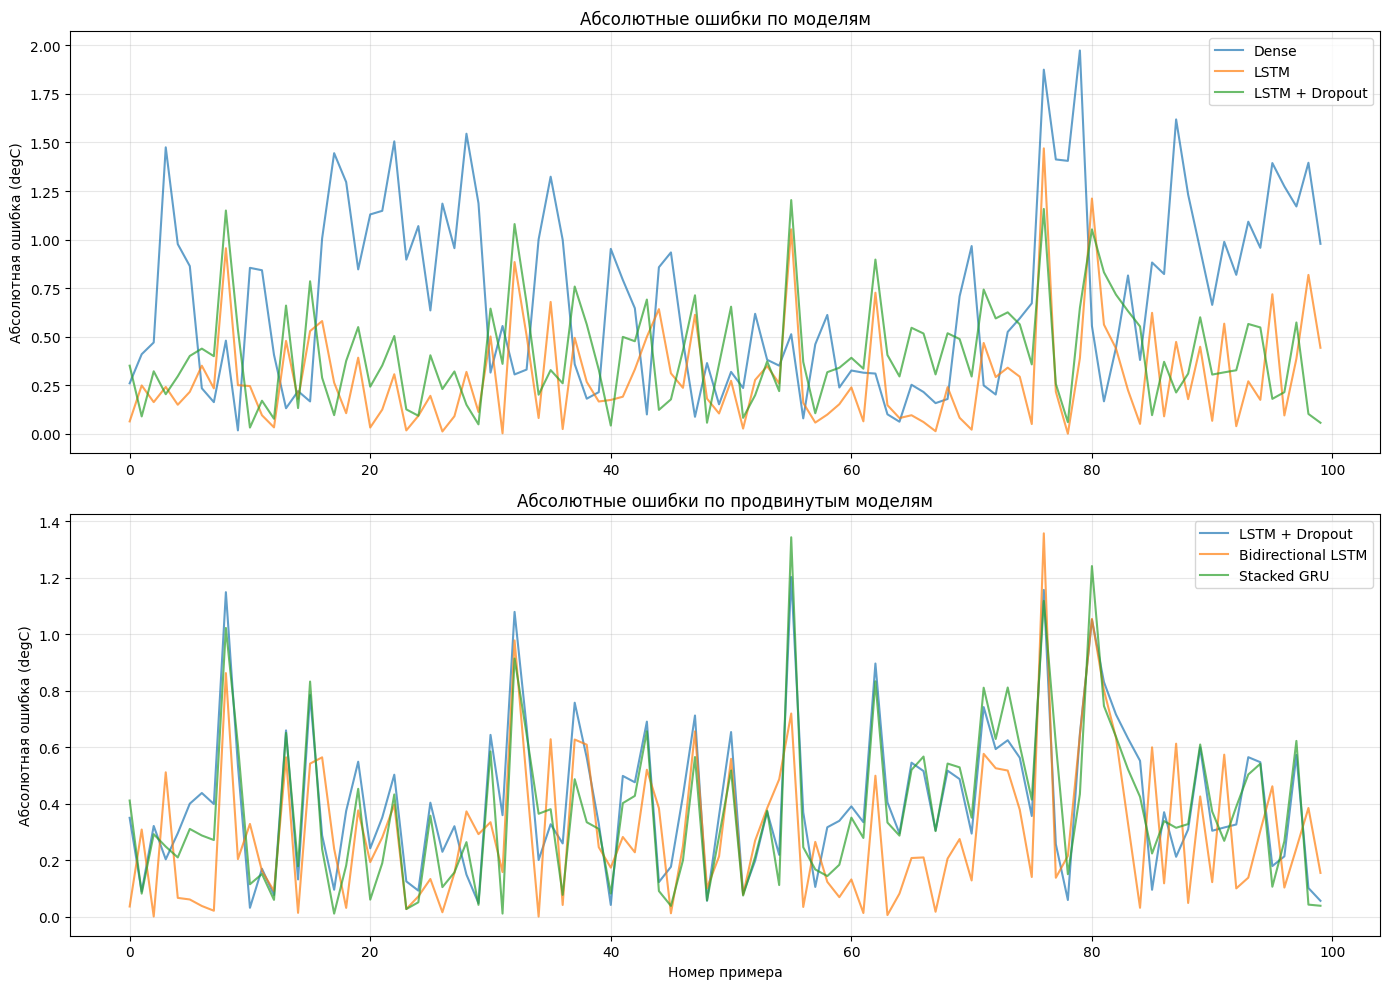

In [66]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

errors_dense = np.abs(preds_dense - targets_dense)
errors_lstm = np.abs(preds_lstm - targets_lstm)
errors_lstm_dropout = np.abs(preds_lstm_dropout - targets_lstm_dropout)

axes[0].plot(errors_dense, label='Dense', alpha=0.7)
axes[0].plot(errors_lstm, label='LSTM', alpha=0.7)
axes[0].plot(errors_lstm_dropout, label='LSTM + Dropout', alpha=0.7)
axes[0].set_title('Абсолютные ошибки по моделям')
axes[0].set_ylabel('Абсолютная ошибка (degC)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

errors_bilstm = np.abs(preds_bilstm - targets_bilstm)
errors_stacked_gru = np.abs(preds_stacked_gru - targets_stacked_gru)

axes[1].plot(errors_lstm_dropout, label='LSTM + Dropout', alpha=0.7)
axes[1].plot(errors_bilstm, label='Bidirectional LSTM', alpha=0.7)
axes[1].plot(errors_stacked_gru, label='Stacked GRU', alpha=0.7)
axes[1].set_title('Абсолютные ошибки по продвинутым моделям')
axes[1].set_xlabel('Номер примера')
axes[1].set_ylabel('Абсолютная ошибка (degC)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [67]:
print("=" * 60)
print("Сравнение моделей")
print("=" * 60)
print(f"{'Модель':<25} {'MAE (degC)':<15} {'RMSE (degC)':<15}")
print("-" * 60)

models_results = [
    ('Dense', preds_dense, targets_dense),
    ('Conv1D', preds_conv, targets_conv),
    ('LSTM', preds_lstm, targets_lstm),
    ('LSTM + Dropout', preds_lstm_dropout, targets_lstm_dropout),
    ('Stacked GRU', preds_stacked_gru, targets_stacked_gru),
    ('Bidirectional LSTM', preds_bilstm, targets_bilstm)
]

best_mae = float('inf')
best_model_name = ''

for name, preds, targets in models_results:
    mae = np.mean(np.abs(preds - targets))
    rmse = np.sqrt(np.mean((preds - targets)**2))
    print(f"{name:<25} {mae:<15.3f} {rmse:<15.3f}")
    if mae < best_mae:
        best_mae = mae
        best_model_name = name

print("-" * 60)
print(f"\nЛучшая модель: {best_model_name} (MAE: {best_mae:.3f} degC)")

Сравнение моделей
Модель                    MAE (degC)      RMSE (degC)    
------------------------------------------------------------
Dense                     0.697           0.835          
Conv1D                    1.386           1.708          
LSTM                      0.299           0.403          
LSTM + Dropout            0.410           0.487          
Stacked GRU               0.377           0.465          
Bidirectional LSTM        0.305           0.401          
------------------------------------------------------------

Лучшая модель: LSTM (MAE: 0.299 degC)


## Авторегрессивный многошаговый прогноз

До сих пор мы предсказывали только **одно** следующее значение температуры (+1 час). Посмотрим, как модели справляются с прогнозом на много шагов вперёд.

**Идея авторегрессии:** прогноз модели снова подаётся на вход как самое свежее значение температуры, окно сдвигается, и модель делает следующий прогноз.

**Важные детали:**

- модели обучены на **нормированной** температуре, поэтому выход модели тоже нормированный: `T_degC = out * std[1] + mean[1]`; в окно при обратной связи кладём нормированное значение;
- шаг прогноза равен `sampling_rate` (1 час), окно `sequence_length = 120`;
- истинные значения берём из **полного** ряда `temperature` (сырые °C) со смещением среза тестового набора, чтобы у последних примеров было реальное будущее;
- авторегрессия подменяет только канал температуры (индекс 1), остальные признаки просто сдвигаются из истории.

С ростом горизонта ошибка накапливается — это ожидаемое поведение одношаговых моделей.


In [68]:
def predict_multistep(model, dataset, start_index, index=0, horizon=24):
    """
    Авторегрессивный прогноз на horizon шагов (шаг = sampling_rate = 1 ч).
    Возвращает (preds_h, true_h) — прогноз и факт в градусах Цельсия.

    Модель обучена на нормированной температуре, поэтому её выход нормирован:
    T_degC = out * std[1] + mean[1]. В окно кладём уже нормированное значение.
    start_index — смещение среза датасета в полном ряду
    (для test_dataset это num_train_samples + num_val_samples).
    """
    model.eval()
    with torch.no_grad():
        sample_x, _ = dataset[index]
        seq_in = sample_x.unsqueeze(0).to(device)
        preds_h = []
        for _ in range(horizon):
            out = model(seq_in)                          # нормированная температура
            p_norm = float(out.squeeze().item())
            preds_h.append(p_norm * std[1] + mean[1])    # прогноз в °C
            last = seq_in[:, -1:, :].clone()
            last[0, 0, 1] = p_norm                       # обратная связь — нормированная
            seq_in = torch.cat([seq_in[:, 1:, :], last], dim=1)

    # истину берём из ПОЛНОГО ряда (сырые °C), а не из среза датасета
    base = start_index + index * sampling_rate + sequence_length * sampling_rate
    true_h = [temperature[min(base + step * sampling_rate, len(temperature) - 1)]
              for step in range(horizon)]
    return np.array(preds_h), np.array(true_h)


In [69]:
horizon = 48
test_start = num_train_samples + num_val_samples

# оставляем запас горизонта, чтобы у каждого примера было реальное будущее
max_idx = len(test_dataset) - 1 - horizon
eval_indices = np.linspace(0, max_idx, 50, dtype=int)
plot_index = int(len(test_dataset) // 2)

models_multistep = [
    ('LSTM + Dropout', model_lstm_dropout),
    ('LSTM', model_lstm),
    ('Conv1D', model_conv),
    ('Dense', model_dense),
    ('Stacked GRU', model_stacked_gru),
    ('Bidirectional LSTM', model_bilstm),
]

res, plot_curves = [], {}
for name, m in models_multistep:
    errs = []
    for idx in eval_indices:
        ph, th = predict_multistep(m, test_dataset, test_start, index=int(idx), horizon=horizon)
        errs.append(np.abs(ph - th))
    mae_h = float(np.mean(np.stack(errs)))
    res.append((name, mae_h))
    plot_curves[name] = predict_multistep(m, test_dataset, test_start,
                                          index=plot_index, horizon=horizon)

print(f"MAE авторегрессивного прогноза на {horizon} ч вперёд (среднее по {len(eval_indices)} примерам):")
print("-" * 55)
for name, mae_h in res:
    print(f"{name:20s} {mae_h:6.2f} degC")


MAE авторегрессивного прогноза на 48 ч вперёд (среднее по 50 примерам):
-------------------------------------------------------
LSTM + Dropout         3.62 degC
LSTM                   3.65 degC
Conv1D                 3.16 degC
Dense                  3.56 degC
Stacked GRU            3.60 degC
Bidirectional LSTM     3.60 degC


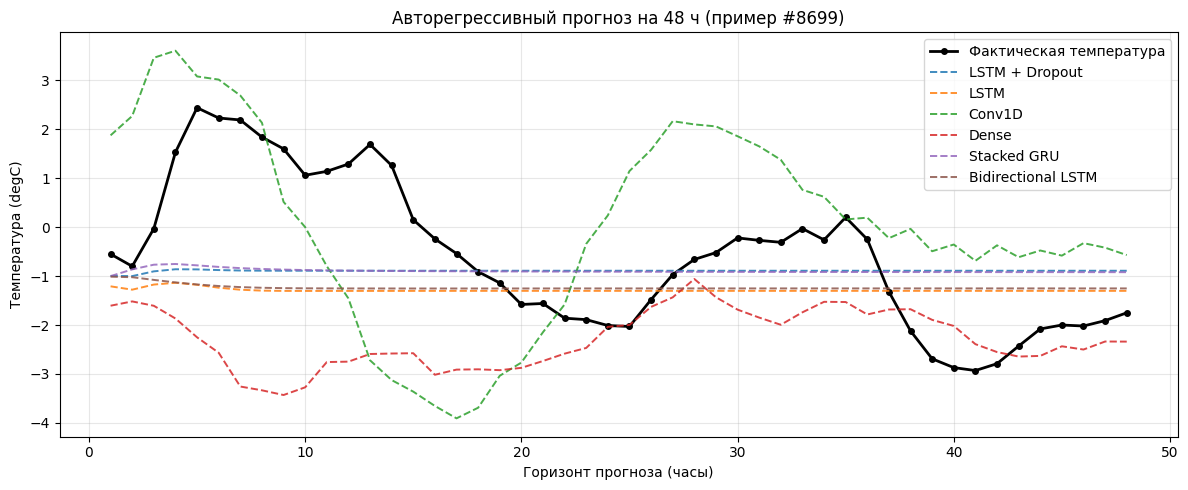

In [70]:
fig, ax = plt.subplots(figsize=(12, 5))
hours = np.arange(1, horizon + 1)

_, th = plot_curves[models_multistep[0][0]]
ax.plot(hours, th, 'ko-', label='Фактическая температура', linewidth=2, markersize=4)

for name, (ph, _) in plot_curves.items():
    ax.plot(hours, ph, '--', label=name, linewidth=1.4, alpha=0.85)

ax.set_xlabel('Горизонт прогноза (часы)')
ax.set_ylabel('Температура (degC)')
ax.set_title(f'Авторегрессивный прогноз на {horizon} ч (пример #{plot_index})')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
